# Task 3 – NumPy, Pandas and Matplotlib
Week 1 Assessment | Python 

### Import Necessary Libraries

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. NumPy array operations

In [2]:
marks = np.array([
    [80, 75, 90],
    [85, 90, 80],
    [70, 65, 75],
    [95, 85, 90]
])

print("Shape:", marks.shape)
print("Student averages:", marks.mean(axis=1))
print("Subject averages:", marks.mean(axis=0))

# Broadcasting adds 5 marks to every subject score
grace_marks = marks + 5
print("Marks after 5 grace marks:\n", grace_marks)

weights = np.array([0.3, 0.3, 0.4])
weighted_scores = np.dot(marks, weights)
print("Weighted scores:", weighted_scores)


Shape: (4, 3)
Student averages: [81.66666667 85.         70.         90.        ]
Subject averages: [82.5  78.75 83.75]
Marks after 5 grace marks:
 [[ 85  80  95]
 [ 90  95  85]
 [ 75  70  80]
 [100  90  95]]
Weighted scores: [82.5 84.5 70.5 90. ]


## 2. Load the Employee data

In [3]:
employee_csv = Path(r"C:\Users\Admin\Desktop\Training\week1-assessment\data\employee.csv")
df = pd.read_csv(employee_csv)

print("First five rows:")
display(df.head())

print("DataFrame information:")
df.info()


First five rows:


,id,name,department,salary,city
0,1,Arun,Sales,30000,Chennai
1,2,Priya,HR,45000,Chennai
2,3,Rahul,IT,60000,Bangalore
3,4,Divya,IT,75000,Chennai
4,5,Karthik,Finance,90000,Mumbai


DataFrame information:
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          8 non-null      int64
 1   name        8 non-null      str  
 2   department  8 non-null      str  
 3   salary      8 non-null      int64
 4   city        8 non-null      str  
dtypes: int64(2), str(3)
memory usage: 452.0 bytes


In [4]:
# Statistical summary
display(df.describe())

# loc: label-based row/column selection
display(df.loc[0:2, ["name", "salary"]])

# iloc: position-based row/column selection
display(df.iloc[0:3, 0:3])

# Filter employees earning more than 50,000
display(df[df["salary"] > 50000])


,id,salary
count,8.00000,8.000000
mean,4.50000,58500.000000
std,2.44949,18913.336187
min,1.00000,30000.000000
25%,2.75000,47250.000000
50%,4.50000,56000.000000
75%,6.25000,69750.000000
max,8.00000,90000.000000


,name,salary
0,Arun,30000
1,Priya,45000
2,Rahul,60000


,id,name,department
0,1,Arun,Sales
1,2,Priya,HR
2,3,Rahul,IT


,id,name,department,salary,city
2,3,Rahul,IT,60000,Bangalore
3,4,Divya,IT,75000,Chennai
4,5,Karthik,Finance,90000,Mumbai
5,6,Meena,Sales,52000,Bangalore
6,7,Suresh,IT,68000,Chennai


## 3. Create department data

In [5]:

departments = pd.DataFrame({
    "department": ["Sales", "HR", "IT", "Finance", "Marketing"],
    "head": ["Ravi", "Anu", "Kumar", "Priya", "Vijay"],
    "budget": [500000, 300000, 800000, 600000, 400000]
})

departments.to_csv(r"C:\Users\Admin\Desktop\Training\week1-assessment\data\departments.csv", index=False)
display(departments)


,department,head,budget
0,Sales,Ravi,500000
1,HR,Anu,300000
2,IT,Kumar,800000
3,Finance,Priya,600000
4,Marketing,Vijay,400000


In [6]:
#Add missing values and a duplicate, then clean the data
df = pd.read_csv(r"C:\Users\Admin\Desktop\Training\week1-assessment\data\employee.csv")

# Add two missing salaries and one duplicate row
df.loc[0, "salary"] = np.nan
df.loc[1, "salary"] = np.nan
df = pd.concat([df, df.iloc[[2]]], ignore_index=True)

print("Rows before cleaning:", len(df))
print("Missing salaries before cleaning:", df["salary"].isna().sum())

Rows before cleaning: 9
Missing salaries before cleaning: 2


In [7]:
# Correct data types
df["id"] = pd.to_numeric(df["id"], errors="raise").astype("int64")
df["name"] = df["name"].astype("string")
df["department"] = df["department"].astype("category")
df["city"] = df["city"].astype("category")
df["salary"] = pd.to_numeric(df["salary"], errors="coerce")

In [8]:

# Fill missing salaries with the median
median_salary = df["salary"].median()
df["salary"] = df["salary"].fillna(median_salary)

# Remove duplicate rows
df = df.drop_duplicates().copy()

In [9]:
# Convert salary to integer after missing values are filled
df["salary"] = df["salary"].astype("int64")

print("Rows after cleaning:", len(df))
print("Missing salaries after cleaning:", df["salary"].isna().sum())
display(df)

Rows after cleaning: 8
Missing salaries after cleaning: 0


,id,name,department,salary,city
0,1,Arun,Sales,60000,Chennai
1,2,Priya,HR,60000,Chennai
2,3,Rahul,IT,60000,Bangalore
3,4,Divya,IT,75000,Chennai
4,5,Karthik,Finance,90000,Mumbai
5,6,Meena,Sales,52000,Bangalore
6,7,Suresh,IT,68000,Chennai
7,8,Anitha,HR,48000,Mumbai


In [10]:
#Calculate headcount, average salary, and maximum salary for each department.
department_summary = df.groupby("department", observed=True).agg(
    headcount=("id", "count"),
    average_salary=("salary", "mean"),
    maximum_salary=("salary", "max")
)

display(department_summary)


,headcount,average_salary,maximum_salary
department,,,
Finance,1,90000.000000,90000
HR,2,54000.000000,60000
IT,3,67666.666667,75000
Sales,2,56000.000000,60000


## 4. Merge employee and department data

In [11]:
departments = pd.read_csv(r"C:\Users\Admin\Desktop\Training\week1-assessment\data\departments.csv")

inner_join = pd.merge(df, departments, on="department", how="inner")
left_join = pd.merge(df, departments, on="department", how="left")
outer_join = pd.merge(df, departments, on="department", how="outer", indicator=True)

print("Inner join:")
display(inner_join)

print("Left join:")
display(left_join)

print("Outer join:")
display(outer_join)


Inner join:


,id,name,department,salary,city,head,budget
0,1,Arun,Sales,60000,Chennai,Ravi,500000
1,2,Priya,HR,60000,Chennai,Anu,300000
2,3,Rahul,IT,60000,Bangalore,Kumar,800000
3,4,Divya,IT,75000,Chennai,Kumar,800000
4,5,Karthik,Finance,90000,Mumbai,Priya,600000
5,6,Meena,Sales,52000,Bangalore,Ravi,500000
6,7,Suresh,IT,68000,Chennai,Kumar,800000
7,8,Anitha,HR,48000,Mumbai,Anu,300000


Left join:


,id,name,department,salary,city,head,budget
0,1,Arun,Sales,60000,Chennai,Ravi,500000
1,2,Priya,HR,60000,Chennai,Anu,300000
2,3,Rahul,IT,60000,Bangalore,Kumar,800000
3,4,Divya,IT,75000,Chennai,Kumar,800000
4,5,Karthik,Finance,90000,Mumbai,Priya,600000
5,6,Meena,Sales,52000,Bangalore,Ravi,500000
6,7,Suresh,IT,68000,Chennai,Kumar,800000
7,8,Anitha,HR,48000,Mumbai,Anu,300000


Outer join:


,id,name,department,salary,city,head,budget,_merge
0,5.0,Karthik,Finance,90000.0,Mumbai,Priya,600000,both
1,2.0,Priya,HR,60000.0,Chennai,Anu,300000,both
2,8.0,Anitha,HR,48000.0,Mumbai,Anu,300000,both
3,3.0,Rahul,IT,60000.0,Bangalore,Kumar,800000,both
4,4.0,Divya,IT,75000.0,Chennai,Kumar,800000,both
5,7.0,Suresh,IT,68000.0,Chennai,Kumar,800000,both
6,NaN,<NA>,Marketing,NaN,NaN,Vijay,400000,right_only
7,1.0,Arun,Sales,60000.0,Chennai,Ravi,500000,both
8,6.0,Meena,Sales,52000.0,Bangalore,Ravi,500000,both


In [12]:

no_employee_departments = outer_join.loc[
    outer_join["id"].isna(), "department"
].drop_duplicates()

print("Departments with no employees:")
print(no_employee_departments.tolist())

Departments with no employees:
['Marketing']


## 5. Create and save four charts

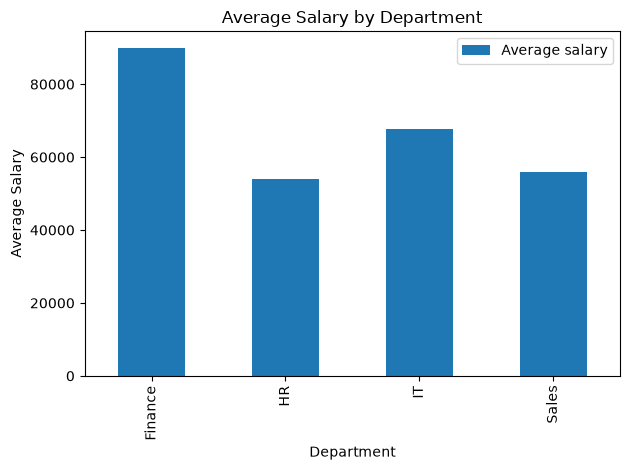

In [13]:
# Bar chart: average salary by department
department_salary = df.groupby("department", observed=True)["salary"].mean()

department_salary.plot(
    kind="bar",
    label="Average salary"
)
plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.legend()
plt.tight_layout()
plt.savefig(r"C:\Users\Admin\Desktop\Training\week1-assessment\reports\bar_chart.png", dpi=150)
plt.show()


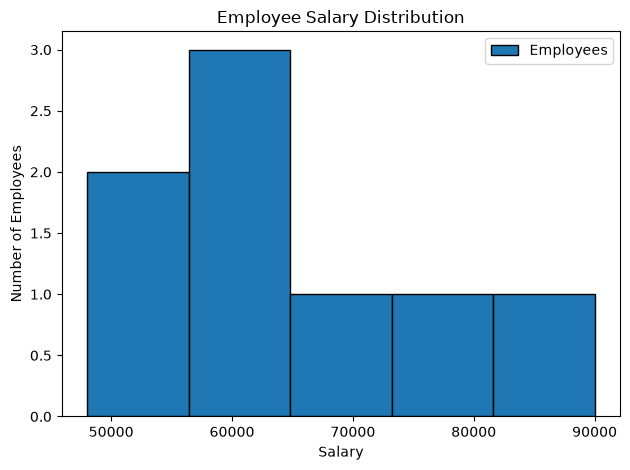

In [14]:
# Histogram: salary distribution
plt.figure()
plt.hist(df["salary"], bins=5, edgecolor="black", label="Employees")
plt.title("Employee Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.legend()
plt.tight_layout()
plt.savefig(r"C:\Users\Admin\Desktop\Training\week1-assessment\reports\histogram.png", dpi=150)
plt.show()


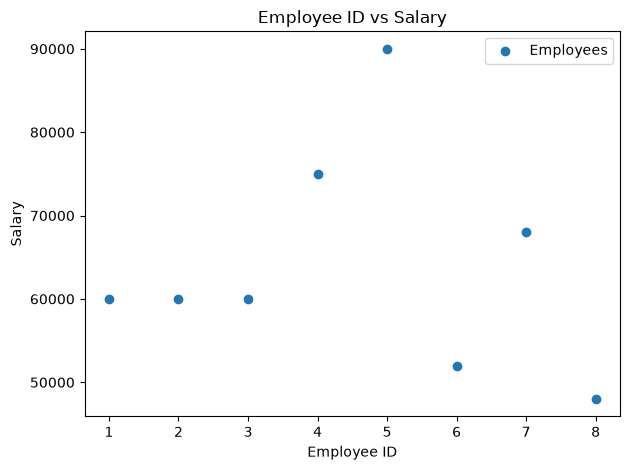

In [15]:
# Scatter plot: employee ID versus salary
plt.figure()
plt.scatter(df["id"], df["salary"], label="Employees")
plt.title("Employee ID vs Salary")
plt.xlabel("Employee ID")
plt.ylabel("Salary")
plt.legend()
plt.tight_layout()
plt.savefig(r"C:\Users\Admin\Desktop\Training\week1-assessment\reports\scatter_chart.png", dpi=150)
plt.show()


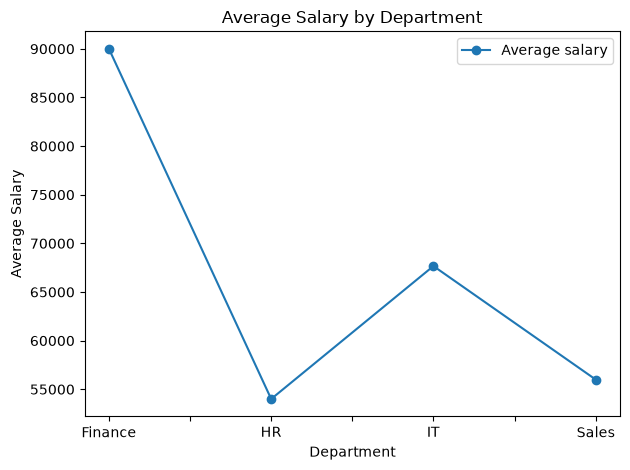

In [16]:
# Line chart: average salary by department
plt.figure()
department_salary.plot(
    kind="line",
    marker="o",
    label="Average salary"
)
plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary")
plt.legend()
plt.tight_layout()
plt.savefig(r"C:\Users\Admin\Desktop\Training\week1-assessment\reports\line_chart.png", dpi=150)
plt.show()


## 6. Chart insights

- **Bar chart:** Finance has the highest average salary among the four departments.
- **Histogram:** Salaries are spread across several salary levels, with a smaller number of higher-paid employees.
- **Scatter plot:** Employee ID does not show a meaningful relationship with salary.
- **Line chart:** Average salary differs by department, with Finance having the highest average.
